# Galaxy rotation: orbits $r(\phi)$
1. Field equation for $m(r)$ and $r(\tau)$
2. $m(r)$
3. Rewrite in terms of $\phi$ (using $\dot\phi = -L_1/(m r^2)$ and $\ddot r$ from `scratch/geodesic-tau-to-phi-dependence.ipynb`)
4. Integrate $r(\phi)$ numerically and plot

## Setup

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import RK45
from IPython.display import display, Math

# render sympy output as LaTeX/MathJax in the notebook
sp.init_printing(use_latex='mathjax')


def show(expr):
    """pprint replacement: render `expr` as LaTeX."""
    display(Math(sp.latex(expr)))


# symbols
r, tau, rs = sp.symbols(r'r \tau r_s', positive=True)
E0, L0 = sp.symbols('E_0 L_0', positive=True)   # constants in m(r)
E1, L1 = sp.symbols('E_1 L_1', positive=True)   # constants in the geodesic; L1 also in phidot = -L1/(m r^2)
c = sp.Symbol('c')                              # integration constant of m(r)
rd, rdd = sp.symbols('rdot rddot', real=True)   # dr/dtau, d²r/dtau²
rp, rpp = sp.symbols(r'\frac{\partial\ r}{\partial\ \phi} \frac{\partial^2r}{\partial\phi^2}', real=True)  # dr/dphi, d²r/dphi²
m = sp.Function('m')(r)
m_s = sp.Symbol('m', positive=True)             # plain symbol for m, used in the r̈ expression

## 1. Field equation
with $N(r) = 1 - r_s/r$:
$$0=\ddot{r}+\dot{r}^2\left(\frac{r_s}{2N(r) r^2}\right)+\frac{r^3 \dot{r}^2}{L_0^2-r_sr E_0^2 }+\frac{r^3-r^2 r_s}{L_0^2-r_sr E_0^2}\left(\frac{L_1^2-L_0^2}{r^3}-\frac{r_s\left(E_1^2-E_0^2\right)}{r^2}\right)$$

In [2]:
N = 1 - rs/r
D = L0**2 - rs*r*E0**2
eq = sp.Eq(0, rdd
              + rd**2 * rs/(2*N*r**2)
              + r**3*rd**2/D
              + (r**3 - r**2*rs)/D * ((L1**2 - L0**2)/r**3 - rs*(E1**2 - E0**2)/r**2))
show(eq)

<IPython.core.display.Math object>

## 2. $m(r)$
From `scratch/geodesic-tau-to-phi-dependence.ipynb`:
$$m(r) = \sqrt{c + \frac{r_s E_0^2}{r} - \frac{L_0^2}{r^2}},\qquad
\frac{\partial m}{\partial r} = \frac{1}{m}\left(\frac{L_0^2}{r^3} - \frac{r_s E_0^2}{2 r^2}\right)$$

In [3]:
m_sol = sp.sqrt(c + rs*E0**2/r - L0**2/r**2)
show(sp.Eq(m, m_sol))

dm_dr = (L0**2/r**3 - rs*E0**2/(2*r**2))/m_s    # ∂m/∂r in terms of m
show(sp.Eq(m.diff(r), dm_dr.subs(m_s, m)))
show(sp.simplify(m_sol.diff(r) - dm_dr.subs(m_s, m_sol)))   # should print 0

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [4]:
# beta = m'/m
beta = dm_dr/m_s
show(beta.subs(m_s, m))
show(beta.subs(m_s, m_sol).simplify())

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 3. Switching to $\phi$ as the independent variable
$\ddot r$ and $\dot r$ come from the end of `scratch/geodesic-tau-to-phi-dependence.ipynb`, using $\dot\phi = -\dfrac{L_1}{m(r)\,r^2}$:

$$\dot r = -\frac{L_1}{m r^2}\frac{\partial r}{\partial \phi},\qquad
\ddot r = \frac{L_1^2}{m^2 r^4}\left[\frac{\partial^2 r}{\partial \phi^2} - \left(\frac{2}{r} + \frac{1}{m^2}\left(\frac{L_0^2}{r^3} - \frac{r_s E_0^2}{2 r^2}\right)\right)\left(\frac{\partial r}{\partial \phi}\right)^2\right]$$

$E_0, L_0$ set $m(r)$; $E_1, L_1$ appear in the geodesic and in $\dot\phi$.

In [5]:
rd_phi  = -L1*rp/(m_s*r**2)
rdd_phi = L1**2/(m_s**2*r**4) * (rpp - (2/r + dm_dr/m_s)*rp**2)   # r̈ from the geodesic notebook
show(sp.Eq(rd, rd_phi))
show(sp.Eq(rdd, rdd_phi))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Orbit equation in $\phi$
$$\frac{\partial^2 r}{\partial \phi^2}=\frac{m(r)\, r_s}{2 N(r) r^2}\left(\frac{\partial r}{\partial \phi}\right)^2+m(r) N(r)\left(\left(1-L_0^2 / L_1^2\right) r-\frac{r_s\left(E_1^2-E_0^2\right) r^2}{2 L_1^2}\right)$$
with $N(r) = 1 - r_s/r$ and $m(r)$ from section 2.

In [6]:
# d²r/dphi² as given above, with m -> m_sol and N = 1 - rs/r
rpp_expr = (m_sol*rs/(2*N*r**2) * rp**2
            + m_sol*N*((1 - L0**2/L1**2)*r - rs*(E1**2 - E0**2)*r**2/(2*L1**2)))
ode_2 = sp.Eq(rpp, rpp_expr)
show(ode_2)

<IPython.core.display.Math object>

## 4. Numerical integration

In [7]:
# numerical functions of (r, dr/dphi, parameters)
rpp_func = sp.lambdify((r, rp, rs, L0, E0, L1, E1, c), rpp_expr, 'numpy')
m_func   = sp.lambdify((r, rs, L0, E0, c), m_sol, 'numpy')

### Parameters and initial conditions

In [8]:
params = dict(rs=10, L0=19.2, E0=10.0, L1=21.428459297547853, E1=10.009041703577916, c=2)   # L0,E0: m(r);  L1,E1: geodesic / phidot
r0, rdot0 = 150.0, .0          # initial r and dr/dtau
phi0, phi_max = 0.0, 6*np.pi

In [ ]:
# convert the initial dr/dtau into dr/dphi:  dr/dphi = -rdot * m r^2 / L1
rp0 = -rdot0 * m_func(r0, params['rs'], params['L0'], params['E0'], params['c']) * r0**2 / params['L1']
print(f'initial dr/dphi = {rp0}')

# First-order system: y = [r, dr/dphi]  ->  dy/dphi = [dr/dphi, d²r/dphi²]
def system(phi, y):
    return [y[1], rpp_func(y[0], y[1], params['rs'], params['L0'], params['E0'],
                           params['L1'], params['E1'], params['c'])]

solver = RK45(system, phi0, [r0, rp0], t_bound=phi_max, max_step=0.1, rtol=1e-9, atol=1e-12)

phis, ys = [solver.t], [solver.y.copy()]
while solver.status == 'running':
    solver.step()better file explorer
    phis.append(solver.t)
    ys.append(solver.y.copy())

phi = np.array(phis)
r_sol, rp_sol = np.array(ys).T
print(solver.status)

initial dr/dphi = -0.0
finished


In [10]:
# Standard Schwarzschild orbit with the same rs, L1, r0, rdot0 (m = 1), same RK45 settings.
# Binet form u'' + u = rs/(2 L^2) + (3/2) rs u^2 with u = 1/r, rewritten for r(phi):
#   d²r/dphi² = 2 (dr/dphi)^2 / r + r - rs r^2 / (2 L1^2) - 3 rs / 2
# (E1 does not appear: it is fixed by r0, rdot0 and L1.)
rp0_s = -rdot0 * r0**2 / params['L1']          # dr/dphi = -rdot r^2 / L1  (m = 1)

def system_s(phi, y):
    r_, rp_ = y
    return [rp_, 2*rp_**2/r_ + r_ - params['rs']*r_**2/(2*params['L1']**2) - 1.5*params['rs']]

solver_s = RK45(system_s, phi0, [r0, rp0_s], t_bound=phi_max, max_step=0.1, rtol=1e-9, atol=1e-12)

phis_s, ys_s = [solver_s.t], [solver_s.y.copy()]
while solver_s.status == 'running':
    solver_s.step()
    phis_s.append(solver_s.t)
    ys_s.append(solver_s.y.copy())

phi_s = np.array(phis_s)
r_sol_s, rp_sol_s = np.array(ys_s).T
print(solver_s.status)

finished


### Plot

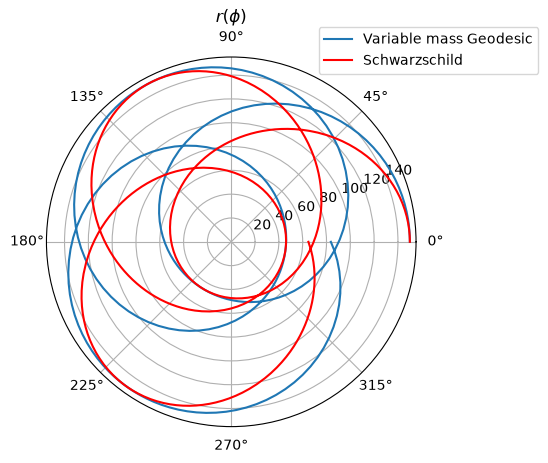

In [11]:
# orbit in the equatorial plane (theta = pi/2), integrated directly in phi
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(phi, r_sol, label='Variable mass Geodesic')
ax.plot(phi_s, r_sol_s, color='red', label='Schwarzschild')
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1))
ax.set_title(r'$r(\phi)$')
plt.show()